# Data Preparation

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit
import matplotlib.pyplot as plt

### Data Loading

In [2]:
data_path = "data\\data.csv"
column_names = ['label']
feature_size = 784  # flattened 28x28 image 
for i in range(feature_size):
    column_names.append(f'x{i}')
data = pd.read_csv(data_path, header=None, names=column_names)

In [3]:
print(f'data.shape : {data.shape}')

nan_cols = data.columns[data.isna().any()].tolist()

condition = data[nan_cols].isna().any(axis=1)
print(f'Number of rows with NaNs : {data[condition].shape[0]}')
print(f"Number of columns with NaNs: {len(nan_cols)}")

data.shape : (8043, 785)
Number of rows with NaNs : 1
Number of columns with NaNs: 409


In [4]:
data.dropna(inplace=True)

In [5]:
data

,label,x0,x1,x2,x3,x4,x5,x6,x7,x8,...,x774,x775,x776,x777,x778,x779,x780,x781,x782,x783
0,7,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8037,8,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8038,5,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8039,4,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8040,6,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### EDA and Data Preprocessing


Summary Distribution:
        Count  Percentage (%)
label                       
0        778            9.67
1        909           11.30
2        838           10.42
3        807           10.03
4        792            9.85
5        726            9.03
6        761            9.46
7        816           10.15
8        792            9.85
9        823           10.23


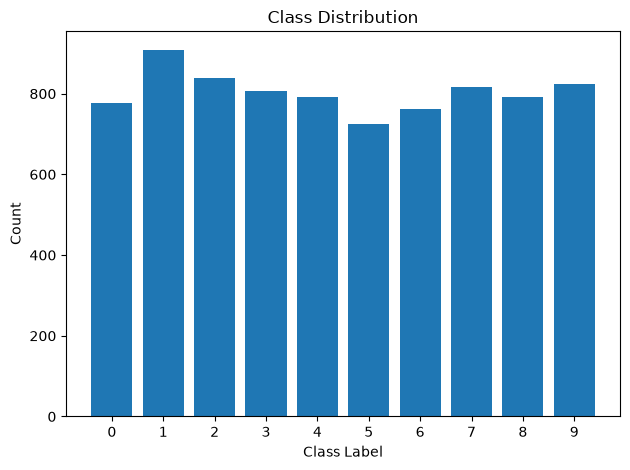

In [6]:
y = data['label']
counts = y.value_counts().sort_index()
proportions = y.value_counts(normalize=True).sort_index() * 100

distribution_df = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': proportions.round(2)
})
print("\nSummary Distribution:\n", distribution_df)

plt.bar(distribution_df.index, distribution_df['Count'])
plt.title('Class Distribution')
plt.xlabel('Class Label')
plt.ylabel('Count')
plt.xticks(distribution_df.index)
plt.tight_layout()
plt.show()

#### Descriptive Stats

In [7]:
# sparse columns
# 

#### Stratified Shuffle Split

In [8]:
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(data, data['label']):
    train_data = data.loc[train_index]
    test_data = data.loc[test_index]

x_train_raw = train_data.drop('label', axis=1)
y_train = train_data['label']

x_test_raw = test_data.drop('label', axis=1)
y_test = test_data['label']


Summary Distribution:
        Count  Percentage (%)
label                       
0        622            9.67
1        727           11.30
2        670           10.42
3        645           10.03
4        634            9.86
5        581            9.03
6        609            9.47
7        653           10.15
8        634            9.86
9        658           10.23


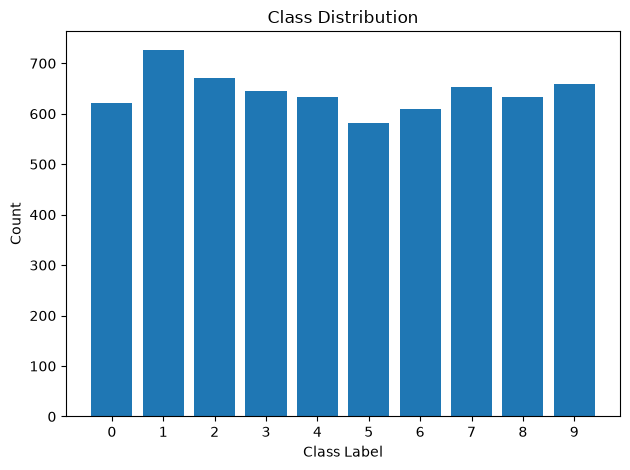

In [9]:
counts = y_train.value_counts().sort_index()
proportions = y_train.value_counts(normalize=True).sort_index() * 100

train_distribution_df = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': proportions.round(2)
})
print("\nSummary Distribution:\n", train_distribution_df)

plt.bar(train_distribution_df.index, train_distribution_df['Count'])
plt.title('Class Distribution')
plt.xlabel('Class Label')
plt.ylabel('Count')
plt.xticks(train_distribution_df.index)
plt.tight_layout()
plt.show()

#### Scaling

In [10]:
scaling_factor = (data.iloc[:,1:].max()).max()

In [11]:
x_train = x_train_raw.to_numpy().astype(np.float32) / scaling_factor
# y_train = y_train.astype(np.int64)

x_test= x_test_raw.to_numpy().astype(np.float32) / scaling_factor
# y_test = y_test.astype(np.int64)

# Models

In [12]:
import copy
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset

In [13]:
# import sys
# from pathlib import Path

# # Add the project root directory to sys.path
# project_root = Path.cwd().parent  # Path("__file__").resolve().parents[1]
# if str(project_root) not in sys.path:
#     sys.path.append(str(project_root))

In [14]:
# %load_ext autoreload
# %autoreload 2

# from models.deep_nn import BaseNN

In [15]:
def get_default_device():
    #  return torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
     return torch.device('cpu')


def _as_tensor(a, dtype):
    if isinstance(a, torch.Tensor):
        return a.to(dtype)
    return torch.as_tensor(np.asarray(a), dtype=dtype)

In [16]:
class BaseNN(nn.Module):
    """Base class: provides mini-batch training, early stopping and batched inference."""
 
    def __init__(self, device=None):
        super().__init__()
        self.device = device or get_default_device()
        self.loss = nn.CrossEntropyLoss()
        self.optimizer = None  # created by subclasses once the parameters exist
 
    # ---- to be implemented by subclasses -------------------------------------------------
    def forward(self, X):
        raise NotImplementedError
 
    # ---- inference -----------------------------------------------------------------------
    @torch.no_grad()
    def _logits(self, X, batch_size=1024):
        self.eval()
        X = _as_tensor(X, torch.float32)
        out = []
        for i in range(0, len(X), batch_size):
            out.append(self.forward(X[i:i + batch_size].to(self.device)).cpu())
        return torch.cat(out)
 
    def predict(self, X, batch_size=1024):
        return self._logits(X, batch_size).argmax(-1).numpy()
 
    def predict_proba(self, X, batch_size=1024):
        return torch.softmax(self._logits(X, batch_size), dim=-1).numpy()
 
    # ---- training ------------------------------------------------------------------------
    def fit(self, X, Y, X_val=None, Y_val=None, epochs=50, batch_size=64,
            patience=5, seed=None, verbose=True):
        """Mini-batch training.
 
        Every epoch the training set is reshuffled and split into batches of `batch_size`;
        one optimizer step is taken per batch. If a validation set is given, the weights
        with the best validation accuracy are restored at the end, and training stops after
        `patience` epochs without improvement (early stopping).
 
        Returns a history dict with train_loss, train_acc, val_loss, val_acc per epoch.
        """
        if seed is not None:
            torch.manual_seed(seed)
            np.random.seed(seed)
 
        X = _as_tensor(X, torch.float32)
        Y = _as_tensor(Y, torch.long)
        g = torch.Generator()
        g.manual_seed(seed if seed is not None else 0)
        loader = DataLoader(TensorDataset(X, Y), batch_size=batch_size,
                            shuffle=True, generator=g)
 
        use_val = X_val is not None and Y_val is not None
        if use_val:
            Xv = _as_tensor(X_val, torch.float32)
            Yv = _as_tensor(Y_val, torch.long)
 
        history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
        best_acc, best_state, wait = -1.0, None, 0
 
        for epoch in range(epochs):
            self.train()
            running_loss, correct, n = 0.0, 0, 0
            for xb, yb in loader:
                xb, yb = xb.to(self.device), yb.to(self.device)
                self.optimizer.zero_grad()
                logits = self.forward(xb)
                loss = self.loss(logits, yb)
                loss.backward()
                self.optimizer.step()
 
                running_loss += loss.item() * len(xb)       # weight by batch size (last batch is smaller)
                correct += (logits.argmax(-1) == yb).sum().item()
                n += len(xb)
            history['train_loss'].append(running_loss / n)
            history['train_acc'].append(correct / n)
 
            msg = (f"epoch {epoch + 1:3d}/{epochs}  "
                   f"loss {history['train_loss'][-1]:.4f}  acc {history['train_acc'][-1]:.4f}")
 
            if use_val:
                logits_v = self._logits(Xv)
                v_loss = self.loss(logits_v, Yv).item()
                v_acc = (logits_v.argmax(-1) == Yv).float().mean().item()
                history['val_loss'].append(v_loss)
                history['val_acc'].append(v_acc)
                msg += f"  | val loss {v_loss:.4f}  val acc {v_acc:.4f}"
 
                if v_acc > best_acc:
                    best_acc, wait = v_acc, 0
                    best_state = copy.deepcopy(self.state_dict())
                else:
                    wait += 1
                    if wait >= patience:
                        if verbose:
                            print(msg)
                            print(f"Early stopping at epoch {epoch + 1} "
                                  f"(best val acc {best_acc:.4f})")
                        break
            if verbose:
                print(msg)
 
        if best_state is not None:
            self.load_state_dict(best_state)
        return history

In [17]:
class FeedForwardNN(BaseNN):
    """Shallow MLP: 784 -> 420 -> 10 (your original architecture)."""
 
    def __init__(self, hidden=420, lr=1e-3, weight_decay=0.0, device=None):
        super().__init__(device)
        self.layers = nn.Sequential(
            nn.Linear(784, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 10),
        )
        self.to(self.device)
        self.optimizer = optim.Adam(self.parameters(), lr=lr, weight_decay=weight_decay)
 
    def forward(self, X):
        return self.layers(X)

In [18]:
class MLP(BaseNN):
    """Deeper MLP with dropout: 784 -> 512 -> 256 -> 128 -> 10."""
 
    def __init__(self, hidden=(512, 256, 128), p=0.3, lr=1e-3, weight_decay=1e-4, device=None):
        super().__init__(device)
        layers, d_in = [], 784
        for h in hidden:
            layers += [nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(p)]
            d_in = h
        layers.append(nn.Linear(d_in, 10))
        self.layers = nn.Sequential(*layers)
        self.to(self.device)
        self.optimizer = optim.Adam(self.parameters(), lr=lr, weight_decay=weight_decay)
 
    def forward(self, X):
        return self.layers(X)

In [19]:
class CNN(BaseNN):
    """Small CNN. Takes flat 784-dim input and reshapes it to (N, 1, 28, 28) internally."""
 
    def __init__(self, p=0.3, lr=1e-3, weight_decay=1e-4, device=None):
        super().__init__(device)
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # -> 16 x 14 x 14
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # -> 32 x 7 x 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p),
            nn.Linear(32 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(128, 10),
        )
        self.to(self.device)
        self.optimizer = optim.Adam(self.parameters(), lr=lr, weight_decay=weight_decay)
 
    def forward(self, X):
        return self.classifier(self.features(X.view(-1, 1, 28, 28)))

# Training

# Metrics

In [20]:
# Common metrics for all models
# NN models need a seperate evaluation function to calculate common metric